In [1]:
import pandas as pd

In [2]:
data = pd.read_csv("ai4i2020.csv")

In [3]:
data.sample(10)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
5047,5048,M19907,M,304.1,313.3,1680,29.3,158,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
3673,3674,H33087,H,302.3,311.7,1449,44.5,152,0,0,0,0,0,0
759,760,M15619,M,296.7,307.8,1537,36.3,233,0,0,0,0,0,0
8667,8668,M23527,M,297.5,308.8,1455,46.1,147,0,0,0,0,0,0
7135,7136,L54315,L,300.5,309.9,1443,48.3,122,0,0,0,0,0,0
4513,4514,L51693,L,302.4,310.3,1900,24.4,113,0,0,0,0,0,0
4267,4268,L51447,L,302.6,311.0,1520,42.8,148,0,0,0,0,0,0
3523,3524,L50703,L,301.8,310.9,1521,39.3,197,0,0,0,0,0,0
3475,3476,L50655,L,301.8,310.7,1644,33.4,68,0,0,0,0,0,0


In [4]:
data.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [5]:
data['Machine failure'].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [6]:
data.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [7]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

data = data[features + ["Machine failure"]]

In [8]:
data.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [9]:
data['Type'].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [10]:
data['Type'] = data['Type'].map({'L': 0, 'M': 1, 'H': 2})

In [11]:
import seaborn as sns

<Axes: >

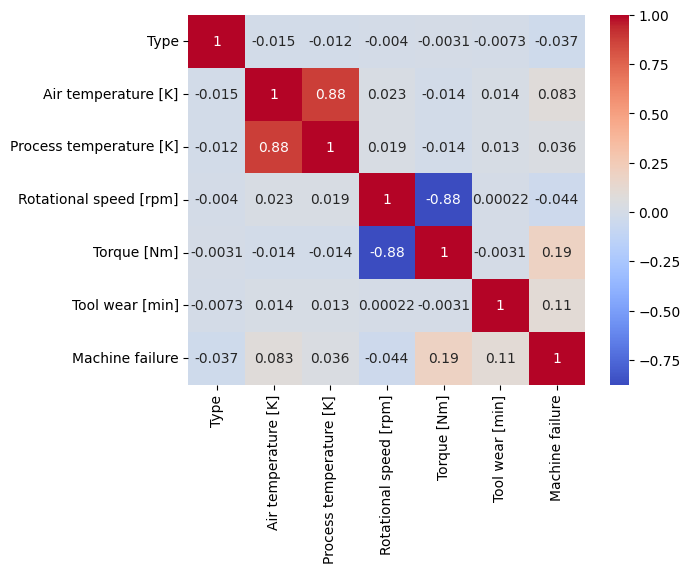

In [12]:
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')

In [13]:
X = data.drop(columns=['Machine failure'], axis=1)
X.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,1,298.1,308.6,1551,42.8,0
1,0,298.2,308.7,1408,46.3,3
2,0,298.1,308.5,1498,49.4,5
3,0,298.2,308.6,1433,39.5,7
4,0,298.2,308.7,1408,40.0,9


In [14]:
y = data['Machine failure']
y.value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [15]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [16]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42))
])

pipeline.fit(x_train, y_train)

,steps,"[('scaler', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,sampling_strategy,'auto'
,random_state,42
,k_neighbors,5
,n_estimators,100


[[1896   43]
 [  18   43]]


<Axes: >

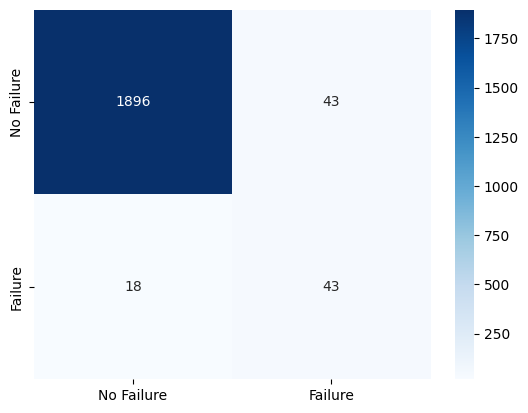

In [19]:
predictions = pipeline.predict(x_test)
confusion = confusion_matrix(y_test, predictions)
print(confusion)

sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues', xticklabels=['No Failure', 'Failure'], yticklabels=['No Failure', 'Failure'])

In [20]:
acc = accuracy_score(y_test, predictions)
print(f"Accuracy: {acc:.4f}")

Accuracy: 0.9695


In [22]:
test_data = [1, 300, 310, 1500, 20, 1000]
test_prediction = pipeline.predict([test_data])
print(f"Test Prediction: {test_prediction[0]}")

Test Prediction: 0


c:\Users\hp\Desktop\Personal Masters\Devops\Industrial Machine Failure Prediction System\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [23]:
import joblib
joblib.dump(pipeline, 'machine_failure_model.pkl')

['machine_failure_model.pkl']